# Failures the main chain cannot see, and a second layer

The closed-loop simulation of this project already protects itself. Its mission manager compares the navigation estimate with the approach corridor, with a closing speed that shrinks with the distance and with the health of its sensors, and flies a collision avoidance maneuver when one of them is exceeded (see the chapter on guidance and control). Every Monte Carlo campaign of the earlier notebooks relied on that protection.

The protection has a blind spot, and this notebook is about it. The abort logic looks at the world through the same estimate that guides the approach. A failure that corrupts the estimate therefore corrupts the guidance and the check at the same time: the servicer does the wrong thing and is convinced it is doing the right one. This is a common-mode failure, and the investigation of the DART mission, which collided with its target in 2005, drew from it the lesson that collision avoidance should rely on information independent of the navigation that guides the approach.

The notebook does two things.

1. It injects three failures of this kind into the simulation, through the new fields of `FailureConfig`, and measures what each does to the approach and to the main abort: a bias on the velocity estimate, a late brake at the last hold point, and a bias on the attitude estimate. For each one it sweeps the size of the failure, because the question is not only whether a failure is dangerous but from which size on.
2. It shows the remedy the simulator now supports: a supervisor, a function called at every step through the `supervisor` argument of `simulate`, that sees only the truth and the force command, never the estimate, and may replace the command or ask the main chain to abort. A minimal supervisor, a watchdog of the closing speed with a range sensor of its own, is enough to turn the first failure from a contact into an abort.

The supervisor here is an illustration of the mechanism, kept deliberately simple. A real safety unit needs its own estimator, a set of rules, a decision logic with persistence and a record of what it did; the point of the notebook is that the simulator can now host one, and that independence is what makes it useful.

In [1]:
%matplotlib inline

from collections import deque

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.gnc.mission_manager import Phase
from ios_mission_planner.sim.config import SimulationConfig
from ios_mission_planner.sim.simulator import simulate
from ios_mission_planner.sim.supervisor import SupervisorDecision

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
COL_TRUE, COL_EST, COL_LIMIT, COL_FAULT = "#1f77b4", "#ff7f0e", "#d62728", "#9467bd"

AXIS = np.array([0.0, -1.0, 0.0])        # outward axis of the chief's port: the deputy closes along -AXIS


def near_hold(seed=0, max_duration=1200.0):
    """
    The deputy at the last hold point S3, 20 m from the port, with small errors: the final
    approach in a few hundred steps, as in the tests of the simulator. The maximum duration
    leaves room for the 900 s of drift that follow a collision avoidance maneuver.
    """
    config = SimulationConfig(seed=seed)
    config.initial.start_hold = 2
    config.initial.position_offset = np.array([0.05, -0.08, -0.04])
    config.initial.velocity_offset = np.array([0.001, -0.001, 0.001])
    config.initial.attitude_error = np.array([0.002, -0.002, 0.003])
    config.initial.navigation_position_error = np.array([0.03, -0.03, 0.02])
    config.initial.navigation_velocity_error = np.array([0.001, 0.001, -0.001])
    config.navigation.initial_position_std = 0.05
    config.navigation.initial_velocity_std = 0.005
    config.guidance.hold_durations = (300.0, 300.0, 60.0)
    config.max_duration = max_duration
    return config


def closing_speed(result):
    return -(result.relative_state[:, 3:] @ AXIS)


def abort_limit(result, config):
    """The closing speed at which the main chain aborts, as a function of the true distance."""
    g = config.guidance
    contact = result.hold_positions[2] - g.hold_distances[2] * AXIS
    distance = np.maximum((result.relative_state[:, :3] - contact) @ AXIS, 0.0)
    return g.abort_closing_speed_factor * (g.closing_speed_floor + g.closing_speed_slope * distance)


nominal = simulate(near_hold())
print(f"nominal final approach: {nominal.outcome} after {nominal.duration:.0f} s, "
      f"axial speed at contact {nominal.contact.values['axial speed [m/s]']:.3f} m/s, "
      f"lateral misalignment {100 * nominal.contact.values['lateral misalignment [m]']:.1f} cm")

nominal final approach: docked after 346 s, axial speed at contact 0.076 m/s, lateral misalignment 0.1 cm


Without failures, the deputy holds at S3 for a minute, translates 20 m and the ports meet after 346 s, at 7.6 cm/s and within a millimetre of the axis. Every experiment below starts from this run, with one thing changed.

## A biased velocity estimate

**Why.** A constant error on the estimated velocity is the failure behind DART. It is also the hardest kind for the main chain to notice: the relative navigation corrects its position with every measurement, but a velocity error that the measurements do not contradict, for instance one introduced after the filter, in the software that hands the estimate to guidance, passes straight through.

**How.** The fields `navigation_velocity_bias_start`, `navigation_velocity_bias_duration` and `navigation_velocity_bias` add a constant vector, in the LVLH frame, to the velocity estimate that the mission manager, the guidance, the control and the abort logic receive. The filter underneath keeps tracking the truth, so its measurements cannot remove the bias. The bias is injected 30 s after the start of the final approach and points along the outward port axis: the deputy believes it closes more slowly than it does, the worst direction, because the guidance then accelerates to restore the planned speed.

**What is measured.** The true closing speed, the closing speed the software believes, and the closing speed at which the main chain would abort, all along the approach; then, for a range of bias sizes, the outcome, the largest excess of the true closing speed over the abort limit, and the conditions at contact.

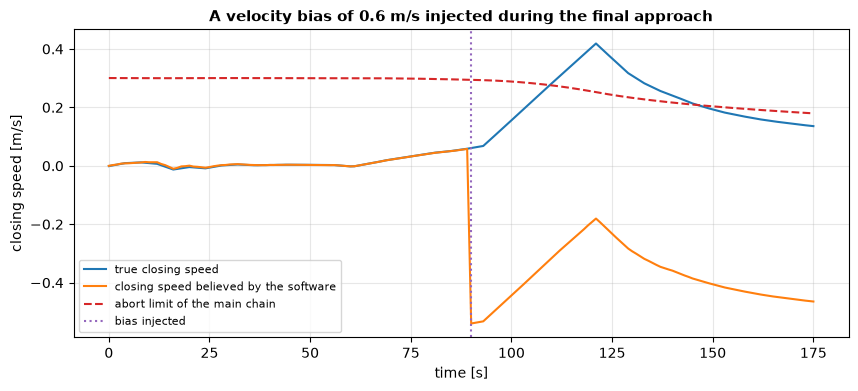

outcome contact out of limits, abort reason None; true closing speed above the abort limit for 37 s, by up to 0.17 m/s; axial speed at contact 0.137 m/s against a limit of 0.1 m/s


In [2]:
def with_velocity_bias(bias, seed=0):
    config = near_hold(seed)
    config.failures.navigation_velocity_bias_start = 90.0
    config.failures.navigation_velocity_bias_duration = 1e6
    config.failures.navigation_velocity_bias = bias * AXIS
    return config


config = with_velocity_bias(0.6)
dart = simulate(config)
believed = -(dart.relative_estimate[:, 3:] @ AXIS)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dart.t, closing_speed(dart), color=COL_TRUE, label="true closing speed")
ax.plot(dart.t, believed, color=COL_EST, label="closing speed believed by the software")
ax.plot(dart.t, abort_limit(dart, config), color=COL_LIMIT, ls="--", label="abort limit of the main chain")
ax.axvline(90.0, color=COL_FAULT, ls=":", label="bias injected")
ax.set_xlabel("time [s]"); ax.set_ylabel("closing speed [m/s]"); ax.legend(fontsize=8)
ax.set_title("A velocity bias of 0.6 m/s injected during the final approach")
plt.show()

excess = closing_speed(dart) - abort_limit(dart, config)
print(f"outcome {dart.outcome}, abort reason {dart.abort_reason}; true closing speed above the abort limit "
      f"for {int(np.sum(excess > 0))} s, by up to {excess.max():.2f} m/s; axial speed at contact "
      f"{dart.contact.values['axial speed [m/s]']:.3f} m/s against a limit of {config.docking_limits.axial_speed_max} m/s")

At the moment of the injection the software believes the deputy is suddenly backing away at half a metre per second. The guidance accelerates toward the chief to restore the planned approach, and the true closing speed climbs to 0.42 m/s, well above the abort limit, while the closing speed the software believes never comes near it. For 37 s the true speed exceeds the limit, by up to 0.17 m/s, and the abort logic, which compares the believed speed with its limit, stays silent. The ports meet at 0.137 m/s, outside the 0.10 m/s that the mechanism accepts.

In [3]:
print(f"{'bias [m/s]':>10s} {'outcome':>22s} {'abort':>8s} {'max excess [m/s]':>17s} {'axial speed at contact':>23s}")
for bias in (0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8):
    config = with_velocity_bias(bias)
    run = simulate(config)
    excess = (closing_speed(run) - abort_limit(run, config)).max()
    speed = f"{run.contact.values['axial speed [m/s]']:.3f} m/s" if run.contact is not None else "-"
    print(f"{bias:10.1f} {run.outcome:>22s} {str(run.abort_reason is not None):>8s} {excess:17.3f} {speed:>23s}")

bias [m/s]                outcome    abort  max excess [m/s]  axial speed at contact


       0.0                 docked    False            -0.104               0.076 m/s


       0.1                 docked    False            -0.105               0.075 m/s


       0.2                 docked    False            -0.066               0.075 m/s


       0.3                 docked    False            -0.010               0.075 m/s


       0.4                 docked    False             0.047               0.076 m/s
       0.6  contact out of limits    False             0.166               0.137 m/s


       0.8  contact out of limits    False             0.288               0.308 m/s


Small biases are absorbed. Up to 0.3 m/s the deputy still docks within the limits, because the final approach is slow and short and the guidance has time to settle; the true closing speed stays below the abort limit. From 0.4 m/s the true speed exceeds the limit at some point of the approach, yet the contact is still acceptable; from 0.6 m/s the contact is out of limits, and at 0.8 m/s it comes at 0.31 m/s, three times the limit. In no case does the main chain abort: its protection is blind to this failure at any size, which is the point.

## A late brake at the last hold point

**Why.** The forced approach slows the deputy down as it arrives at each hold point. If the command that does so arrives late, because of a software stall or a mode switch that takes longer than planned, the deputy carries its speed past the point where it should have stopped, toward the client. The main chain sees the deputy where it is, so its navigation is right; but its abort checks the closing speed against a limit that, at the speeds of the last metres, is not exceeded.

**How.** With `late_braking_start`, `late_braking_duration` and `late_braking_hold`, once the estimated distance to the chosen hold falls below `late_braking_distance` (1 m by default), the part of the commanded acceleration that slows the deputy along the approach axis is removed for the given delay. The other components are untouched, so the deputy stays on the axis. The fault acts once. Here the deputy starts at the hold point S2, 500 m out, and flies the forced approach to S3.

**What is measured.** How far past S3, toward the client, the deputy goes before it stops, for a range of delays, and whether the main chain aborts.

delay [s]    outcome   abort  past S3 [m]  closest to the port before the go [m]


        0     docked   False         0.05                                  19.95


       30     docked   False         0.63                                  19.37


       60     docked   False         2.12                                  17.88


      120     docked   False         5.08                                  14.92


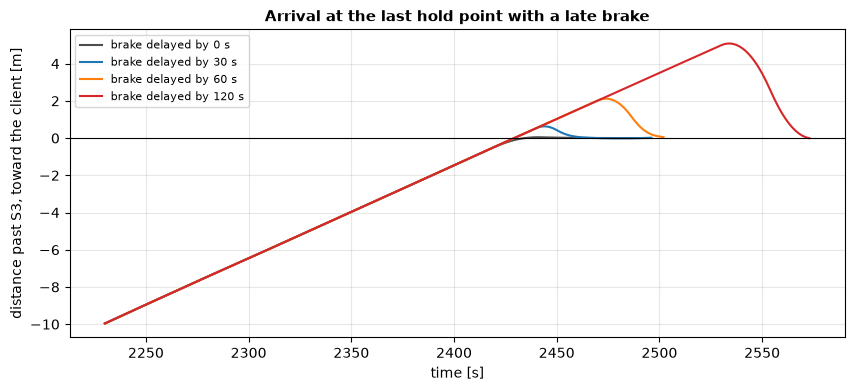

In [4]:
def from_s2(delay, seed=3):
    config = near_hold(seed, max_duration=4000.0)
    config.initial.start_hold = 1
    if delay:
        config.failures.late_braking_start = 0.0
        config.failures.late_braking_duration = delay
    return config


fig, ax = plt.subplots(figsize=(10, 4))
print(f"{'delay [s]':>9s} {'outcome':>10s} {'abort':>7s} {'past S3 [m]':>12s} {'closest to the port before the go [m]':>38s}")
for delay, colour in ((0.0, "0.3"), (30.0, COL_TRUE), (60.0, COL_EST), (120.0, COL_LIMIT)):
    run = simulate(from_s2(delay))
    before_final = run.phase < Phase.FINAL_APPROACH
    past = -((run.relative_state[:, :3] - run.hold_positions[2]) @ AXIS)
    port = run.port_axial[before_final].min()
    print(f"{delay:9.0f} {run.outcome:>10s} {str(run.abort_reason is not None):>7s} {past[before_final].max():12.2f} {port:38.2f}")
    near_s3 = before_final & (np.abs(past) < 10.0)
    ax.plot(run.t[near_s3], past[near_s3], color=colour, label=f"brake delayed by {delay:.0f} s")
ax.axhline(0.0, color="k", lw=0.8)
ax.set_xlabel("time [s]"); ax.set_ylabel("distance past S3, toward the client [m]"); ax.legend(fontsize=8)
ax.set_title("Arrival at the last hold point with a late brake")
plt.show()

The overshoot grows with the delay, slowly at first and then in proportion to it: 0.6 m for a delay of 30 s, 2.1 m for 60 s, 5.1 m for 120 s. In the last case the deputy comes to 14.9 m from the port before the go for the final approach, five metres inside the place where it was supposed to wait. The guidance then brings it back and the docking succeeds, and the main chain never aborts: its navigation is right, and the closing speed of a few centimetres per second is well within its limit. What is broken here is a volume, the space that the deputy may occupy before the go, not a speed, and the main abort does not watch volumes near the hold.

## A biased attitude estimate

**Why.** Every force the servicer commands is converted from the LVLH frame, where guidance thinks, to the body frame, where the thrusters are, with the estimated attitude. If that attitude is wrong, the attitude controller steers the body to the wrong orientation, the thrusters push in rotated directions, and the docking port points off the axis, while every check that compares the estimated attitude with the commanded one finds nothing wrong.

**How.** `attitude_bias_start`, `attitude_bias_duration` and `attitude_bias` rotate, by a rotation vector in the body frame, the attitude estimate used by the attitude controller and by the conversion of the force command; the relative navigation keeps the correct one. `attitude_bias_ramp` lets the error grow over a given time instead of appearing in one step. The distinction matters, and the first experiment shows why: a sudden error is a jump in the estimated pointing error, which the abort logic sees; an error that grows slowly is followed by the controller and stays invisible, as a real drift of an attitude estimate would.

**What is measured.** For a bias appearing at once and for the same bias growing over two minutes, the outcome and the reason of any abort; then, for growing angles, the true pointing error, the fraction of steps in which the relative sensor, whose field of view has a half-angle of 20 degrees, still sees the target, and the lateral misalignment at contact.

In [5]:
def with_attitude_bias(angle_deg, ramp):
    config = near_hold(0)
    config.failures.attitude_bias_start = 0.0
    config.failures.attitude_bias_duration = 1e6
    config.failures.attitude_bias = np.array([0.0, 0.0, np.radians(angle_deg)])
    config.failures.attitude_bias_ramp = ramp
    return config


for ramp in (0.0, 120.0):
    run = simulate(with_attitude_bias(17.0, ramp))
    print(f"17 deg bias, {'in one step' if ramp == 0 else f'over {ramp:.0f} s'}: {run.outcome}, abort reason: {run.abort_reason}")

print()
print(f"{'bias [deg]':>10s} {'outcome':>22s} {'abort reason':>28s} {'true pointing error [deg]':>26s} {'target seen':>12s} {'lateral at contact [cm]':>24s}")
for angle in (0.0, 5.0, 10.0, 17.0, 25.0):
    run = simulate(with_attitude_bias(angle, 120.0))
    later = run.t > 150.0
    lateral = f"{100 * run.contact.values['lateral misalignment [m]']:.1f}" if run.contact is not None else "-"
    print(f"{angle:10.0f} {run.outcome:>22s} {str(run.abort_reason):>28s} "
          f"{np.degrees(np.median(run.attitude_error[later])):26.1f} {100 * run.measurement_valid[later].mean():11.0f}% {lateral:>24s}")

17 deg bias, in one step: aborted, abort reason: attitude error too large


17 deg bias, over 120 s: contact out of limits, abort reason: None

bias [deg]                outcome                 abort reason  true pointing error [deg]  target seen  lateral at contact [cm]


         0                 docked                         None                        0.0         100%                      0.1


         5  contact out of limits                         None                        5.0         100%                      5.4


        10  contact out of limits                         None                       10.0          99%                     10.5


        17  contact out of limits                         None                       17.0          91%                     18.0


        25                aborted   relative measurements lost                       25.0           2%                        -


The same 17 degree error has opposite fates depending on how it appears. In one step it is a jump of the estimated pointing error, and the main chain aborts at once. Grown over two minutes, it is followed by the controller and nobody notices: the true attitude ends up 17 degrees from the command, the docking port with it, and the ports meet 18 cm apart, outside the 10 cm the mechanism accepts.

The sweep shows how the error carries straight into the contact, about a centimetre of lateral misalignment per degree, with the main chain silent from 5 degrees on. At 25 degrees the error is finally noticed, indirectly: the relative sensor, whose boresight now points 25 degrees away from the target, loses it, and after 30 s without measurements the main chain aborts. The protection works only once the failure has grown large enough to blind a sensor.

## A second layer: an independent watchdog

**Why.** The three failures share a pattern: the main chain flies on a wrong picture of the world and its own abort, which looks at the same picture, does not fire. The remedy flown on the European cargo vehicle ATV, and recommended after DART, is a second layer that watches the approach with information of its own. If that layer shares nothing with the main navigation, a failure of the main navigation cannot blind it.

**How.** The simulator calls a supervisor once per step, after the main chain has computed its force command and before the thrusters execute it. The supervisor receives a `SupervisorSample` with the time, the true relative state, the true attitude and the force command, as read-only arrays, and nothing from the main chain's software. It returns `None` to let the main chain act, or a `SupervisorDecision` that replaces the force command, asks for an abort, or both. A supervisor meant to be independent uses the truth only to simulate a sensor of its own, with its own errors and its own random numbers.

The watchdog below is the smallest useful example. Its sensor measures only the distance to the chief, with an error of 2 cm plus 1 percent, from a random stream of its own. It estimates the closing speed as the slope of a straight line fitted to the last ten distances, and compares it with the same speed profile that the main abort uses, $1.5\,(0.12 + 0.004\,d)$ m/s at a distance $d$ from the port. When the measured closing speed exceeds the profile for three consecutive seconds, it asks the main chain to abort, and the main chain flies its usual collision avoidance maneuver.

**What is measured.** On the nominal approach, whether the watchdog stays silent; on the approach with the 0.6 m/s velocity bias, when it fires, what the main chain does, and how close the ports come.

nominal approach with the watchdog: docked, watchdog fired: False


0.6 m/s bias with the watchdog: aborted, abort reason: supervisor request, watchdog fired at 115 s
closest approach of the ports: 8.93 m (without the watchdog the ports touched at 0.137 m/s)
events: [(115.0, 'supervisor request'), (115.0, 'supervisor: abort request (closing speed above the profile)'), (128.0, 'supervisor: released')]


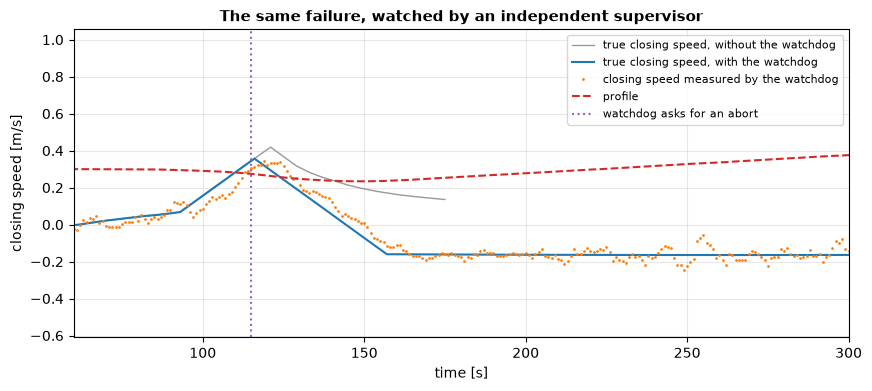

In [6]:
class ClosingSpeedWatchdog:
    """
    A minimal independent supervisor: a range sensor of its own, the closing speed from the slope of
    the last `window` ranges, and an abort request when it exceeds the closing speed profile for
    `persistence` consecutive seconds. It reads the true state only to synthesise its measurement.
    """

    def __init__(self, seed, window=10, persistence=3, floor=0.12, slope=0.004, factor=1.5, contact_range=1.6):
        self.rng = np.random.default_rng(seed + 1000)          # never shared with the main chain
        self.ranges, self.times = deque(maxlen=window), deque(maxlen=window)
        self.persistence, self.count = persistence, 0
        self.floor, self.slope, self.factor, self.contact_range = floor, slope, factor, contact_range
        self.triggered_at, self.history = None, []

    def __call__(self, sample):
        true_range = float(np.linalg.norm(sample.relative_state[:3]))
        self.ranges.append(true_range + (0.02 + 0.01 * true_range) * self.rng.standard_normal())
        self.times.append(sample.t)
        if len(self.ranges) < self.ranges.maxlen:
            return None
        closing = -np.polyfit(np.array(self.times), np.array(self.ranges), 1)[0]
        distance = max(np.mean(self.ranges) - self.contact_range, 0.0)
        limit = self.factor * (self.floor + self.slope * distance)
        self.history.append((sample.t, closing, limit))
        self.count = self.count + 1 if closing > limit else 0
        if self.count >= self.persistence:
            self.triggered_at = sample.t if self.triggered_at is None else self.triggered_at
            return SupervisorDecision(request_abort=True, note="closing speed above the profile")
        return None


quiet = ClosingSpeedWatchdog(seed=0)
watched_nominal = simulate(near_hold(), supervisor=quiet)
print(f"nominal approach with the watchdog: {watched_nominal.outcome}, watchdog fired: {quiet.triggered_at is not None}")

dog = ClosingSpeedWatchdog(seed=0)
saved = simulate(with_velocity_bias(0.6), supervisor=dog)
print(f"0.6 m/s bias with the watchdog: {saved.outcome}, abort reason: {saved.abort_reason}, watchdog fired at {dog.triggered_at:.0f} s")
print(f"closest approach of the ports: {saved.port_axial.min():.2f} m (without the watchdog the ports touched at "
      f"{dart.contact.values['axial speed [m/s]']:.3f} m/s)")
print("events:", [(t, note) for t, phase, note in saved.events if t >= 60 and note])

history = np.array(dog.history)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dart.t, closing_speed(dart), color="0.6", lw=1, label="true closing speed, without the watchdog")
ax.plot(saved.t, closing_speed(saved), color=COL_TRUE, label="true closing speed, with the watchdog")
ax.plot(history[:, 0], history[:, 1], ".", ms=2, color=COL_EST, label="closing speed measured by the watchdog")
ax.plot(history[:, 0], history[:, 2], color=COL_LIMIT, ls="--", label="profile")
ax.axvline(dog.triggered_at, color=COL_FAULT, ls=":", label="watchdog asks for an abort")
ax.set_xlim(60, 300); ax.set_xlabel("time [s]"); ax.set_ylabel("closing speed [m/s]"); ax.legend(fontsize=8)
ax.set_title("The same failure, watched by an independent supervisor")
plt.show()

On the nominal approach the watchdog never fires: its measured closing speed, noisy by a few centimetres per second, stays below the profile. With the velocity bias it fires at 115 s, 25 s after the injection and while the true closing speed is crossing the profile. The mission manager starts its collision avoidance maneuver at once, the ports never come closer than 8.9 m, and the run ends with an abort instead of a contact out of limits. The events of the run record both sides: the supervisor's request and the abort of the main chain, both at 115 s.

The watchdog then lets go, at 128 s, because the deputy is moving away and the measured closing speed is negative; the abort is not undone, since the main chain keeps flying its maneuver. Three choices make it work: a sensor that the failure cannot reach, a limit taken from the same speed profile as the main abort, and three seconds of persistence, which keep the noise of a single measurement from triggering an abort.

## Summary

A failure that corrupts what the main chain believes, rather than what it does, defeats the protection built into the main chain, because that protection looks through the same belief. The three failures injected here show it in three ways. A velocity bias drives the deputy into the port too fast with the abort logic silent at every size; a late brake carries it five metres past its hold point toward the chief; a slowly growing attitude error steers its port off the axis by a centimetre per degree, noticed only when it blinds the relative sensor.

The supervisor argument of `simulate` gives the simulation a place for an independent second layer, and the minimal watchdog above, with a range sensor of its own and twenty lines of logic, turns the first failure from a contact into an abort, with no false alarm on the nominal approach. It is an illustration, not a safety unit: it watches one quantity, would not catch the late brake or the attitude error, and has no record of its decisions. A unit that watches the volumes, the speeds, the free drift and the plumes of the thrusters with the same independence is the natural next step, and the hook is what it plugs into.